In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.insert(0, '../code')
from plot_config import PLOT_COLORS

In [2]:
df = pd.read_csv('../results/dual_cf_isolation/effusion/summary_densenet_cf16.csv')
df

,model,config,mean_auc,std_auc,fold_aucs
0,LR,B1,0.7362,0.0094,"0.7461,0.7384,0.7222,0.7289,0.7457"
1,LR,B4_single,0.8259,0.0113,"0.8367,0.8359,0.8083,0.8169,0.8315"
2,LR,B4_dual,0.8192,0.0110,"0.8315,0.8281,0.8019,0.8116,0.8230"
3,LR,M3_single,0.8264,0.0114,"0.8371,0.8368,0.8086,0.8174,0.8320"
4,LR,M3_dual,0.8211,0.0109,"0.8320,0.8316,0.8038,0.8138,0.8243"
5,RF,B1,0.7530,0.0099,"0.7538,0.7668,0.7388,0.7457,0.7599"
6,RF,B4_single,0.8262,0.0107,"0.8341,0.8342,0.8135,0.8128,0.8365"
7,RF,B4_dual,0.8257,0.0097,"0.8356,0.8301,0.8132,0.8150,0.8349"
8,RF,M3_single,0.8308,0.0113,"0.8396,0.8422,0.8120,0.8239,0.8364"
9,RF,M3_dual,0.8295,0.0115,"0.8408,0.8367,0.8146,0.8164,0.8391"


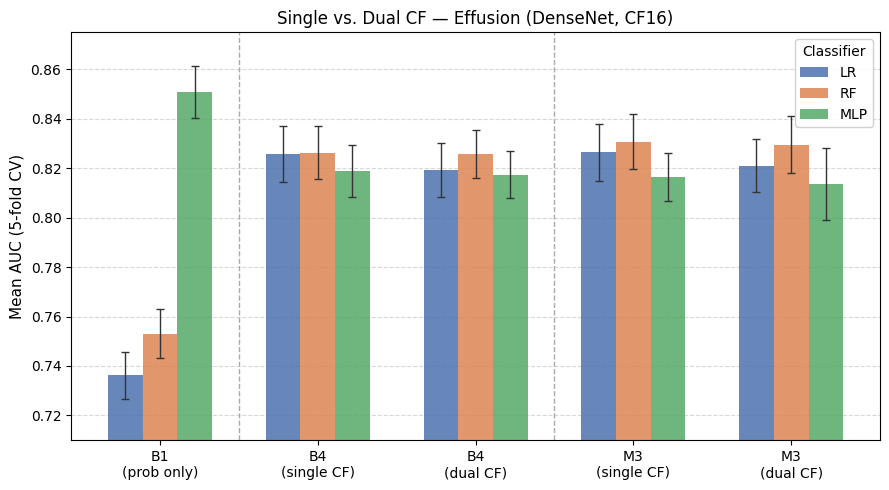

In [8]:
CONFIG_ORDER = ['B1', 'B4_single', 'B4_dual', 'M3_single', 'M3_dual']
CONFIG_LABELS = {
    'B1':        'B1\n(prob only)',
    'B4_single': 'B4\n(single CF)',
    'B4_dual':   'B4\n(dual CF)',
    'M3_single': 'M3\n(single CF)',
    'M3_dual':   'M3\n(dual CF)',
}
MODELS = ['LR', 'RF', 'MLP']
MODEL_COLORS = {'LR': '#4C72B0', 'RF': '#DD8452', 'MLP': '#55A868'}

# Base config key (strip _single/_dual suffix) for colour lookup
def base_key(cfg):
    return cfg.split('_')[0]

fig, ax = plt.subplots(figsize=(9, 5))

n_configs = len(CONFIG_ORDER)
n_models  = len(MODELS)
width = 0.22
x = np.arange(n_configs)

for i, model in enumerate(MODELS):
    sub = df[df['model'] == model].set_index('config')
    means = [sub.loc[c, 'mean_auc'] if c in sub.index else np.nan for c in CONFIG_ORDER]
    stds  = [sub.loc[c, 'std_auc']  if c in sub.index else 0      for c in CONFIG_ORDER]
    offset = (i - (n_models - 1) / 2) * width
    bars = ax.bar(x + offset, means, width, yerr=stds, capsize=3,
                  label=model, color=MODEL_COLORS[model], alpha=0.85,
                  error_kw=dict(elinewidth=1, ecolor='#333333'))

# Vertical divider between baselines (B4) and methods (M3)
ax.axvline(x=.5, color='#aaaaaa', linewidth=1, linestyle='--')
ax.axvline(x=2.5, color='#aaaaaa', linewidth=1, linestyle='--')

ax.set_xticks(x)
ax.set_xticklabels([CONFIG_LABELS[c] for c in CONFIG_ORDER], fontsize=10)
ax.set_ylabel('Mean AUC (5-fold CV)', fontsize=11)
ax.set_title('Single vs. Dual CF — Effusion (DenseNet, CF16)', fontsize=12)
ax.set_ylim(0.71, 0.875)
ax.legend(title='Classifier', framealpha=0.9)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig('../results/dual_cf_isolation/effusion/dual_cf_isolation_effusion.pdf', dpi=150, bbox_inches='tight')
plt.savefig('../results/dual_cf_isolation/effusion/dual_cf_isolation_effusion.png', dpi=150, bbox_inches='tight')
plt.show()